11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder (Functional)            │ (None, 32)             │       104,608 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder (Functional)            │ (None, 784)            │       105,360 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 209,968 (820.19 KB)

 Trainable params: 209,968 (820.19 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/5
235/235 ━━━━━━━━━━━━━━━━━━━━ 6s 16ms/step - loss: 0.2274 - val_loss: 0.1455
Epoch 2/5
235/235 ━━━━━━━━━━━━━━━━━━━━ 5s 15ms/step - loss: 0.1318 - val_loss: 0.1192
Epoch 3/5
235/235 ━━━━━━━━━━━━━━━━━━━━ 5s 20ms/step - loss: 0.1152 - val_loss: 0.1095
Epoch 4/5
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 15ms/step - loss: 0.1079 - val_loss: 0.1050
Epoch 5/5
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 15ms/step - loss: 0.1034 - val_loss: 0.1006


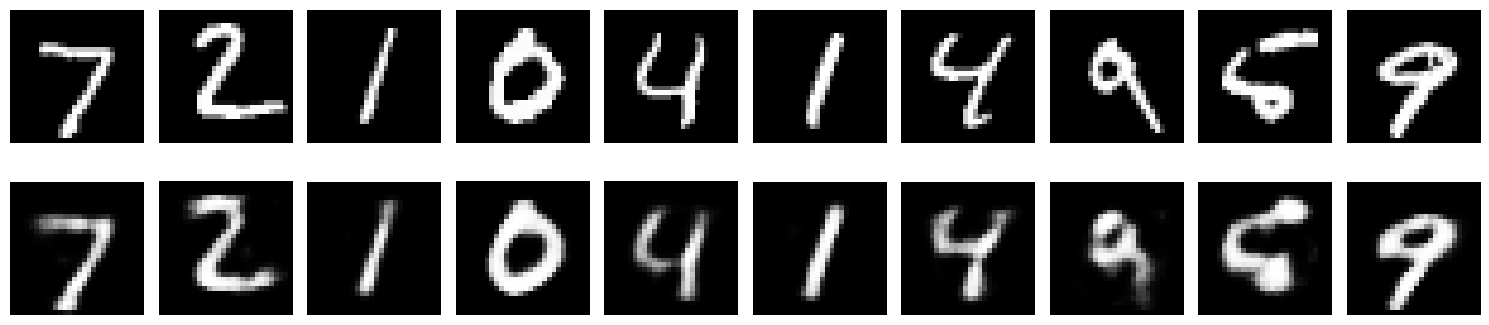

In [1]:

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import matplotlib.pyplot as plt

# 1. Load MNIST dataset
(x_train, _), (x_test, _) = keras.datasets.mnist.load_data()

# 2. Normalize pixel values and flatten images
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

x_train = x_train.reshape(-1, 784)
x_test = x_test.reshape(-1, 784)

# 3. Build the encoder
encoder_input = keras.Input(shape=(784,))

x = layers.Dense(128, activation="relu")(encoder_input)
latent = layers.Dense(32, activation="relu")(x)

encoder = keras.Model(encoder_input, latent, name="encoder")

# 4. Build the decoder
decoder_input = keras.Input(shape=(32,))

x = layers.Dense(128, activation="relu")(decoder_input)
decoder_output = layers.Dense(
    784, activation="sigmoid"
)(x)

decoder = keras.Model(decoder_input, decoder_output, name="decoder")

# 5. Combine encoder and decoder
autoencoder_input = keras.Input(shape=(784,))
encoded = encoder(autoencoder_input)
reconstructed = decoder(encoded)

autoencoder = keras.Model(
    autoencoder_input,
    reconstructed,
    name="autoencoder"
)

# 6. Compile
autoencoder.compile(
    optimizer="adam",
    loss="binary_crossentropy"
)

autoencoder.summary()

# 7. Train: input and target are the same images
history = autoencoder.fit(
    x_train,
    x_train,
    epochs=5,
    batch_size=256,
    shuffle=True,
    validation_data=(x_test, x_test)
)

# 8. Reconstruct test images
reconstructed_images = autoencoder.predict(
    x_test[:10], verbose=0
)

# 9. Display original vs reconstructed images
plt.figure(figsize=(15, 4))

for i in range(10):
    # Original
    plt.subplot(2, 10, i + 1)
    plt.imshow(x_test[i].reshape(28, 28), cmap="gray")
    plt.axis("off")
    if i == 0:
        plt.ylabel("Original")

    # Reconstructed
    plt.subplot(2, 10, i + 11)
    plt.imshow(
        reconstructed_images[i].reshape(28, 28),
        cmap="gray"
    )
    plt.axis("off")
    if i == 0:
        plt.ylabel("Reconstructed")

plt.tight_layout()
plt.show()
